<a href="https://colab.research.google.com/github/Anjanique-Knight/AjGIS/blob/main/PS2_GIS_2FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

For ps2 I used information available on the NJ DCA website to find affordable housing developments in Atlantic County.  As a current resident of Atlantic County, I thought it would be more digestable to focus on one county's municipalities and affordable housing devleopment.  Using the same methods I can replicate several maps of NJ counties and use DCA's housing devleopment lists to plot the developments throughout NJ.  

After simplifying the map to just Southern NJ Counties,. I simplified it down to just Atlantic Counties

After finding this data I updated the Atlantic Housing Development sheet to include cities assocciated with development sites and used Nominatim to convert locations to x/y or Long/Lat points to show on the Atlantic County map.

Once established I used a NJ.gov stats to get population density for Atlantic County municipalities.

Future maps may include average rental unit mixes(# of bedrooms) or average rents against affordable housing developments stats to further establish need.


# Set Up

In [43]:
#!pip install geopandas

import geopandas as gpd
import zipfile

In [44]:
! wget -O njCO1.zip https://github.com/Anjanique-Knight/AjGIS/raw/refs/heads/main/NJ_Counties_3857_2520527434192953465.zip

--2026-10-12 16:34:18--  https://github.com/Anjanique-Knight/AjGIS/raw/refs/heads/main/NJ_Counties_3857_2520527434192953465.zip
Resolving github.com (github.com)... 140.82.112.3
Connecting to github.com (github.com)|140.82.112.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/Anjanique-Knight/AjGIS/refs/heads/main/NJ_Counties_3857_2520527434192953465.zip [following]
--2026-10-12 16:34:20--  https://raw.githubusercontent.com/Anjanique-Knight/AjGIS/refs/heads/main/NJ_Counties_3857_2520527434192953465.zip
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2128431 (2.0M) [application/zip]
Saving to: ‘njCO1.zip’

njCO1.zip           100%[===================>]   2.03M  --.-KB/s    in 0.06s   

2026-10-1

In [45]:
zip_ref = zipfile.ZipFile('njCO1.zip', 'r'); zip_ref.extractall(); zip_ref.close()

In [46]:
gdf=gpd.read_file('NJ_Counties_3857.shp')

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

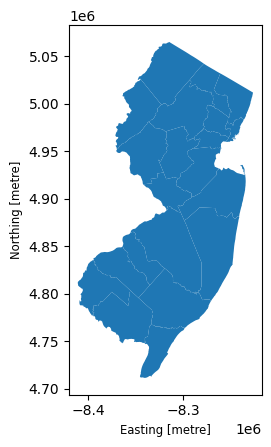

In [47]:
gdf.plot()

In [48]:
import pandas as pd


In [49]:
gdf.head()

,COUNTY,COUNTY_LAB,CO,GNIS_NAME,GNIS,FIPSSTCO,FIPSCO,ACRES,SQ_MILES,POP2020,...,POP2000,POP1990,POP1980,POPDEN2020,POPDEN2010,POPDEN2000,POPDEN1990,POPDEN1980,REGION,geometry
0,ATLANTIC,Atlantic County,ATL,County of Atlantic,882270,34001,1,390813.840968,610.646627,274534,...,252552,275372,204615,450,450,414,451,335,COASTAL,"POLYGON ((-8312713.282 4820790.797, -8312708.3..."
1,BERGEN,Bergen County,BER,County of Bergen,882271,34003,3,153491.054911,239.829773,955732,...,884118,829592,849843,3985,3774,3686,3459,3544,NORTHEASTERN,"POLYGON ((-8227143.658 5009857.214, -8227168.3..."
2,BURLINGTON,Burlington County,BUR,County of Burlington,882272,34005,5,524901.239967,820.158187,461860,...,423394,395066,362542,563,547,516,482,442,SOUTHERN,"POLYGON ((-8315414.947 4892462.575, -8315385.2..."
3,CAMDEN,Camden County,CAM,County of Camden,882273,34007,7,145594.972008,227.492144,523485,...,508932,532498,471650,2301,2258,2237,2341,2073,SOUTHERN,"POLYGON ((-8352650.407 4865191.068, -8352634.3..."
4,CAPE MAY,Cape May County,CAP,County of Cape May,882274,34009,9,183125.841721,286.134128,95263,...,102326,95089,82266,333,340,358,332,288,COASTAL,"POLYGON ((-8333334.7 4767465.182, -8333326.647..."


# Isolating South Jersey

In [50]:
snj_counties=['ATLANTIC', 'CUMBERLAND', 'CAMDEN', 'BURLINGTON', 'CAPE MAY', 'SALEM', 'GLOUCESTER', 'OCEAN']

In [51]:
from numpy import copy
gdf[gdf['COUNTY'].isin(snj_counties)].copy

<bound method GeoDataFrame.copy of         COUNTY         COUNTY_LAB   CO             GNIS_NAME    GNIS FIPSSTCO  \
0     ATLANTIC    Atlantic County  ATL    County of Atlantic  882270    34001   
2   BURLINGTON  Burlington County  BUR  County of Burlington  882272    34005   
3       CAMDEN      Camden County  CAM      County of Camden  882273    34007   
4     CAPE MAY    Cape May County  CAP    County of Cape May  882274    34009   
5   CUMBERLAND  Cumberland County  CUM  County of Cumberland  882275    34011   
7   GLOUCESTER  Gloucester County  GLO  County of Gloucester  882277    34015   
14       OCEAN       Ocean County  OCE       County of Ocean  882279    34029   
16       SALEM       Salem County  SAL       County of Salem  882233    34033   

   FIPSCO          ACRES    SQ_MILES  POP2020  ...  POP2000  POP1990  POP1980  \
0       1  390813.840968  610.646627   274534  ...   252552   275372   204615   
2       5  524901.239967  820.158187   461860  ...   423394   395066   362542   
3       7  145594.972008  227.492144   523485  ...   508932   532498   471650   
4       9  183125.841721  286.134128    95263  ...   102326    95089    82266   
5      11  321149.036972  501.795370   154152  ...   146438   138053   132866   
7      15  215075.237102  336.055058   302294  ...   254673   230082   199917   
14     29  485076.500519  757.932032   637229  ...   510916   443424   356502   
16     33  222157.767414  347.121512    64837  ...    64285    65294    64676   

    POPDEN2020  POPDEN2010  POPDEN2000  POPDEN1990  POPDEN1980    REGION  \
0          450         450         414         451         335   COASTAL   
2          563         547         516         482         442  SOUTHERN   
3         2301        2258        2237        2341        2073  SOUTHERN   
4          333         340         358         332         288   COASTAL   
5          307         313         292         275         265  SOUTHERN   
7          900         858         758         685         595  SOUTHERN   
14         841         761         674         585         470   COASTAL   
16         187         190         185         188         186  SOUTHERN   

                                             geometry  
0   POLYGON ((-8312713.282 4820790.797, -8312708.3...  
2   POLYGON ((-8315414.947 4892462.575, -8315385.2...  
3   POLYGON ((-8352650.407 4865191.068, -8352634.3...  
4   POLYGON ((-8333334.7 4767465.182, -8333326.647...  
5   POLYGON ((-8355847.558 4803471.275, -8352785.3...  
7   POLYGON ((-8363274.44 4848913.536, -8363252.89...  
14  POLYGON ((-8266732.882 4890220.9, -8266724.401...  
16  POLYGON ((-8394264.296 4834757.726, -8394253.8...  

[8 rows x 21 columns]>

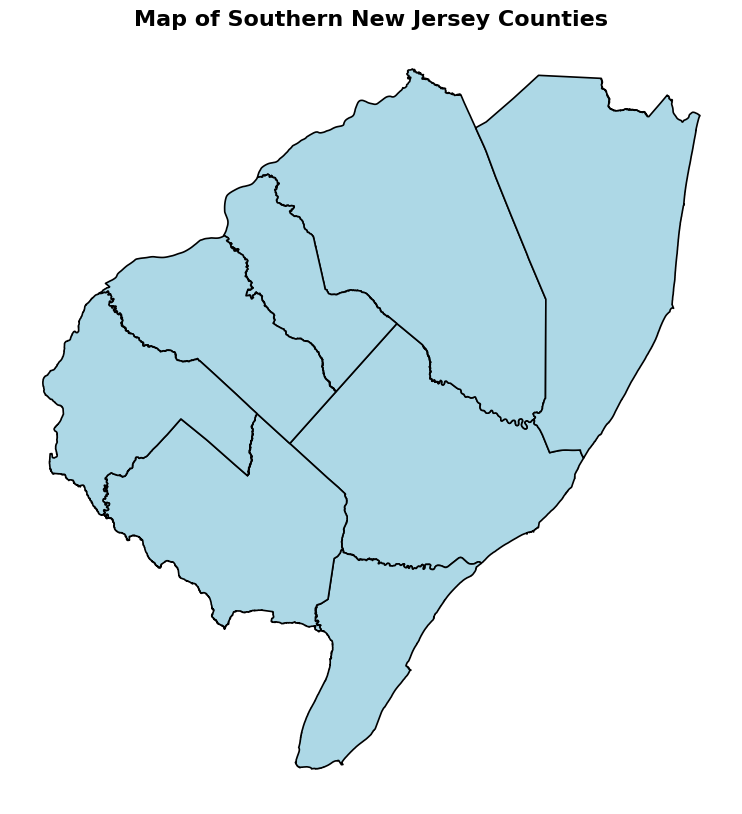

In [52]:
import matplotlib.pyplot as plt

# Filter the GeoDataFrame to keep only the Southern NJ counties
snj_gdf = gdf[gdf['COUNTY'].isin(snj_counties)].copy()

fig, ax = plt.subplots(figsize=(10, 10))
snj_gdf.plot(ax=ax, edgecolor='black', color='lightblue', linewidth=1.2)

plt.title('Map of Southern New Jersey Counties', fontsize=16, fontweight='bold')
plt.axis('off')
plt.show()

# Isolating Atlantic County

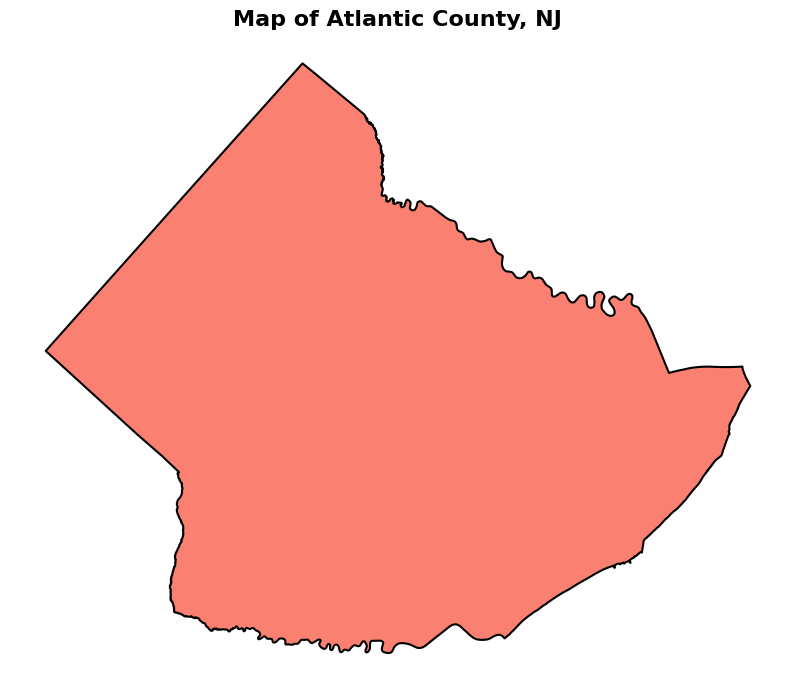

In [53]:
ATLantic = snj_gdf[snj_gdf['COUNTY'] == 'ATLANTIC'].copy()
fig, ax = plt.subplots(figsize=(10, 10))
ATLantic.plot(ax=ax, edgecolor='black', color='salmon', linewidth=1.5)
plt.title('Map of Atlantic County, NJ', fontsize=16, fontweight='bold')
plt.axis('off')
plt.show()

In [54]:
! wget -q -O njMun.zip https://github.com/Anjanique-Knight/AjGIS/raw/refs/heads/main/NJ_Municipal_Boundaries_3424_-6792731789006169525.zip

In [55]:
zip_ref = zipfile.ZipFile('njMun.zip', 'r'); zip_ref.extractall(); zip_ref.close()

In [56]:
gdf=gpd.read_file('NJ_Municipal_Boundaries_3424.shp')

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

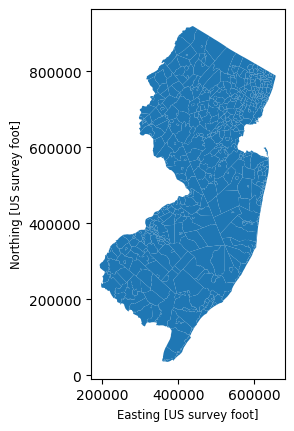

In [57]:
gdf.plot()

In [58]:
import pandas as pd


In [59]:
gdf.head()

,MUN,COUNTY,MUN_LABEL,MUN_TYPE,NAME,GNIS_NAME,GNIS,SSN,MUN_CODE,CENSUS2020,...,POP2010,POP2000,POP1990,POP1980,POPDEN2020,POPDEN2010,POPDEN2000,POPDEN1990,POPDEN1980,geometry
0,CAPE MAY POINT BORO,CAPE MAY,Cape May Point Borough,Borough,Cape May Point Borough,Borough of Cape May Point,885179,0503,0503,3400910330,...,291,241,248,255,1016,970,803,826,850,"POLYGON ((361324.555 36119.591, 361262.564 361..."
1,WEST CAPE MAY BORO,CAPE MAY,West Cape May Borough,Borough,West Cape May Borough,Borough of West Cape May,885435,0512,0512,3400978530,...,1024,1095,1026,1091,854,866,926,868,923,"POLYGON ((371013.281 40519.688, 372330.802 395..."
2,CAPE MAY CITY,CAPE MAY,Cape May City,City,Cape May,City of Cape May,885178,0502,0502,3400910270,...,3607,4034,4668,4853,960,1251,1399,1619,1684,"POLYGON ((385059.21 43411.44, 385135.71 43390...."
3,WILDWOOD CREST BORO,CAPE MAY,Wildwood Crest Borough,Borough,Wildwood Crest Borough,Borough of Wildwood Crest,885445,0515,0515,3400981200,...,3270,3980,3631,4149,2094,2208,2688,2452,2802,"POLYGON ((397386.178 55797.446, 397386.526 557..."
4,WEST WILDWOOD BORO,CAPE MAY,West Wildwood Borough,Borough,West Wildwood Borough,Borough of West Wildwood,885441,0513,0513,3400980210,...,603,448,453,360,1484,1657,1231,1245,990,"POLYGON ((401502.81 61708.99, 401592.22 61615...."


In [60]:
# Filter to keep only municipalities in Atlantic County
atlantic_mun_gdf = gdf[gdf['COUNTY'] == 'ATLANTIC'].copy()

# Display the first few rows of the filtered GeoDataFrame
display(atlantic_mun_gdf.head())


,MUN,COUNTY,MUN_LABEL,MUN_TYPE,NAME,GNIS_NAME,GNIS,SSN,MUN_CODE,CENSUS2020,...,POP2010,POP2000,POP1990,POP1980,POPDEN2020,POPDEN2010,POPDEN2000,POPDEN1990,POPDEN1980,geometry
13,LONGPORT BORO,ATLANTIC,Longport Borough,Borough,Longport Borough,Borough of Longport,885286,0115,0115,3400141370,...,895,1054,1224,1249,1503,1507,1774,2060,2103,"POLYGON ((487673.252 176134.655, 487479.027 17..."
15,CORBIN CITY,ATLANTIC,Corbin City,City,Corbin City,City of Corbin City,885192,0106,0106,3400115160,...,492,468,412,254,52,55,52,46,28,"POLYGON ((422066.136 176339.873, 422075.89 176..."
16,SOMERS POINT CITY,ATLANTIC,Somers Point City,City,Somers Point,City of Somers Point,885397,0121,0121,3400168430,...,10795,11614,11216,10330,2104,2169,2334,2254,2076,"POLYGON ((464960.373 183097.251, 465071.67 182..."
17,MARGATE CITY,ATLANTIC,Margate City,City,Margate City,City of Margate City,885292,0116,0116,3400143890,...,6354,8193,8431,9179,3258,3893,5020,5166,5624,"POLYGON ((491565.71 185676.12, 491734.11 18545..."
20,VENTNOR CITY,ATLANTIC,Ventnor City,City,Ventnor City,City of Ventnor City,885426,0122,0122,3400175620,...,10650,12910,11005,11704,3613,4178,5064,4317,4591,"POLYGON ((494545.46 189258.23, 494708.26 18925..."


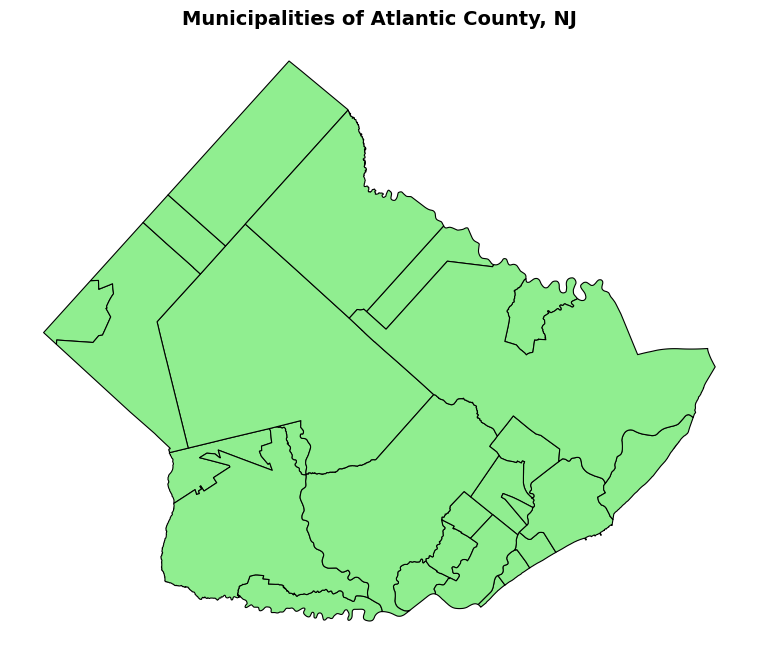

In [61]:
# Filter and plot the municipalities of Atlantic County
import matplotlib.pyplot as plt

# Ensure the filtered GeoDataFrame is defined
atlantic_mun_gdf = gdf[gdf['COUNTY'] == 'ATLANTIC'].copy()

fig, ax = plt.subplots(figsize=(10, 8))
atlantic_mun_gdf.plot(ax=ax, edgecolor='black', color='lightgreen', linewidth=0.8)
plt.title('Municipalities of Atlantic County, NJ', fontsize=14, fontweight='bold')
plt.axis('off')
plt.show()

#Geocoding Atlantic County Affordable Housing

In [62]:
ATLhome=pd.read_excel('https://github.com/Anjanique-Knight/AjGIS/raw/refs/heads/main/atlantic.xlsx')
ATLhome=ATLhome[0:5]
ATLhome

,o,seq,ltd,source,notes,proj_no,pro_no_2,Unnamed: 7,development / aka,aka,...,phone,agent,agent address,area_2,phone_2,website,Unnamed: 35,program,date,seq.1
0,2,30001,NaN,HUD,NaN,NJ39Q971009,035HD084,NaN,Absecon consumer group home,NaN,...,780-1175,Collaborative Support Programs of NJ,"11 Spring St, Freehold 08977",(908),272-5365,CSPNJ,NaN,Section 202,NaT,30001
1,3,30002,NaN,HUD,NaN,NJ39Q081006,035HD069,NaN,Caring group home (2008),NaN,...,484-7050,Caring Inc,"407 W Delilah Rd, Pleasantville 08232",(609),677-0022,Home (caringinc.net),NaN,Section 202,NaT,30002
2,4,30003,NaN,HUD,NaN,NJ39Q101004,035HD074,NaN,Caring group home (2010),NaN,...,484-7050,Caring Inc,"407 W Delilah Rd, Pleasantville 08232",(609),677-0022,Home (caringinc.net),NaN,Section 202,NaT,30003
3,5,20001,NaN,tax credit,NaN,010109937,NaN,NaN,Clayton Mill Run Apts,5 bldgs; facility id 010109937,...,385-2745,Conifer Realty,"20000 Horizon Way, ste 180, Mount Laurel 08054",(856),793-2078,Clayton Mill Run - Conifer Realty LLC (conifer...,NaN,tax credit / MtL,NaT,20001
4,6,30005,NaN,HUD,NaN,NJ39RDD1317,NaN,NaN,Visions at Absecon Family & Senior Apts,1 bldg; 24 du,...,780-8314,D & M Property Mgt,"655 Park Av, Freehold 07728",NaN,NaN,NaN,NaN,NaN,NaT,30005


In [63]:
from geopandas.tools import geocode

In [64]:
# Filter out rows with placeholder street names like 'intentional blank'
valid_homes = ATLhome[~ATLhome['street'].astype(str).str.contains('intentional blank', case=False, na=True)].copy()

# Combine valid street, 'City ', and state into address strings
full_addresses = valid_homes['street'].astype(str) + ', ' + valid_homes['City '].astype(str) + ', NJ'

# Geocode the valid addresses
ATLgeo = geocode(full_addresses, provider='nominatim', user_agent='Aj', timeout=5)
ATLgeo.head()

,geometry,address
3,POINT (-74.51256 39.41702),"Rose Hill Drive, Absecon, Atlantic County, New..."
4,POINT (-74.49304 39.43958),"3, School View Drive, Mi-Place at the Shore, A..."


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

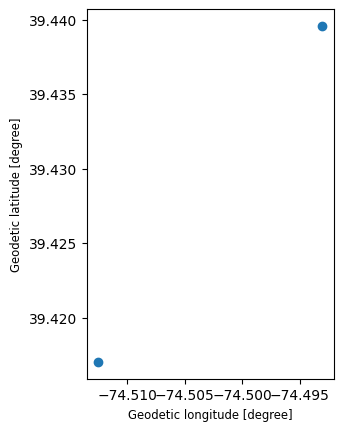

In [65]:
ATLgeo.plot()

In [66]:
import time
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter
import geopandas as gpd
from shapely.geometry import Point
import pandas as pd

# 1. Load the FULL dataset without slicing
ATLhome_full = pd.read_excel('https://github.com/Anjanique-Knight/AjGIS/raw/refs/heads/main/atlantic.xlsx')

# 2. Filter out rows with placeholder street names like 'intentional blank'
valid_homes_full = ATLhome_full[
    ~ATLhome_full['street'].astype(str).str.contains('intentional blank', case=False, na=True)
].copy()

# 3. Combine valid street, 'City ', and state into full address strings
valid_homes_full['full_address'] = valid_homes_full['street'].astype(str) + ', ' + valid_homes_full['City '].astype(str) + ', NJ'

# 4. Initialize Nominatim Geocoder and RateLimiter to enforce 1 second per request
geolocator = Nominatim(user_agent="nj_affordable_housing_mapper_aj")
geocode_with_delay = RateLimiter(geolocator.geocode, min_delay_seconds=1.1, return_value_on_exception=None)

# 5. Geocode the addresses
print(f"Geocoding {len(valid_homes_full)} addresses with a rate-limit delay (takes about 1.5 - 2 minutes). Please wait...")
valid_homes_full['location'] = valid_homes_full['full_address'].apply(geocode_with_delay)

# 6. Extract geometry and clean up results
valid_homes_full['point'] = valid_homes_full['location'].apply(lambda loc: Point(loc.longitude, loc.latitude) if loc else None)
valid_homes_full['address_matched'] = valid_homes_full['location'].apply(lambda loc: loc.address if loc else None)

# Drop rows that failed to geocode
final_geocoded = valid_homes_full.dropna(subset=['point']).copy()

# Convert to GeoDataFrame
ATLgeo_full = gpd.GeoDataFrame(final_geocoded, geometry='point', crs="EPSG:4326")

# Configure pandas to show all rows in display
pd.set_option('display.max_rows', None)

# Display the entire geocoded address list (using 'point' as the geometry column name)
display(ATLgeo_full[['street', 'City ', 'address_matched', 'point']])

Geocoding 92 addresses with a rate-limit delay (takes about 1.5 - 2 minutes). Please wait...


,street,City,address_matched,point
3,600 Rose Hill Dr,Absecon,"Rose Hill Drive, Absecon, Atlantic County, New...",POINT (-74.51256 39.41702)
4,3 School View Dr,Absecon,"3, School View Drive, Mi-Place at the Shore, A...",POINT (-74.49304 39.43958)
5,227 N Vermont Av,Atlantic City,"Charles P. Jeffries Tower, 227, North Vermont ...",POINT (-74.41612 39.37123)
6,334 N Tennesee Av,Atlantic City,"South Tennesee Avenue, Midtown, Inlet, Atlanti...",POINT (-74.42594 39.35893)
7,46 N Connecticut Av,Atlantic City,"46, North Connecticut Avenue, Uptown, Inlet, A...",POINT (-74.41922 39.36751)
8,1000 Arctic Av,Atlantic City,"Altman Terrace, 1000, Arctic Avenue, Uptown, I...",POINT (-74.42457 39.36531)
11,1330 Mediterranean Av,Atlantic City,"1330, Mediterranean Avenue, Midtown North, Wes...",POINT (-74.42996 39.36653)
12,732 N Maryland Av,Atlantic City,"732, North Maryland Avenue, Midtown North, Inl...",POINT (-74.42764 39.3732)
13,1313 Baltic Av,Atlantic City,"1313, Baltic Avenue, Midtown North, Westside, ...",POINT (-74.42899 39.36544)
14,721 N Atlantic Av,Atlantic City,"Atlantic Avenue, Southeast Inlet, Inlet, Atlan...",POINT (-74.41266 39.36836)


In [67]:
ATLgeo_full.head()

,o,seq,ltd,source,notes,proj_no,pro_no_2,Unnamed: 7,development / aka,aka,...,phone_2,website,Unnamed: 35,program,date,seq.1,full_address,location,point,address_matched
3,5,20001,NaN,tax credit,NaN,010109937,NaN,NaN,Clayton Mill Run Apts,5 bldgs; facility id 010109937,...,793-2078,Clayton Mill Run - Conifer Realty LLC (conifer...,NaN,tax credit / MtL,NaT,20001,"600 Rose Hill Dr, Absecon, NJ","(Rose Hill Drive, Absecon, Atlantic County, Ne...",POINT (-74.51256 39.41702),"Rose Hill Drive, Absecon, Atlantic County, New..."
4,6,30005,NaN,HUD,NaN,NJ39RDD1317,NaN,NaN,Visions at Absecon Family & Senior Apts,1 bldg; 24 du,...,NaN,NaN,NaN,NaN,NaT,30005,"3 School View Dr, Absecon, NJ","(3, School View Drive, Mi-Place at the Shore, ...",POINT (-74.49304 39.43958),"3, School View Drive, Mi-Place at the Shore, A..."
5,8,10001,NaN,PHA,NaN,NJ014,NaN,NaN,Atlantic City Housing Authority,NaN,...,344-1107,"Welcome to Atlantic City Housing Authority, NJ...",NaN,Public Housing,2022-01-12,10001,"227 N Vermont Av, Atlantic City, NJ","(Charles P. Jeffries Tower, 227, North Vermont...",POINT (-74.41612 39.37123),"Charles P. Jeffries Tower, 227, North Vermont ..."
6,9,90001,NaN,MtL,NaN,NaN,NaN,NaN,334 N Tennesee Av Apts,NaN,...,348-3188,NaN,NaN,MtL,NaT,90001,"334 N Tennesee Av, Atlantic City, NJ","(South Tennesee Avenue, Midtown, Inlet, Atlant...",POINT (-74.42594 39.35893),"South Tennesee Avenue, Midtown, Inlet, Atlanti..."
7,10,20002,NaN,tax credit,NaN,NJA20123008,LITC #302,NaN,46 N Connecticut Av Apts,NaN,...,233-6942,NaN,NaN,tax credit,NaT,20002,"46 N Connecticut Av, Atlantic City, NJ","(46, North Connecticut Avenue, Uptown, Inlet, ...",POINT (-74.41922 39.36751),"46, North Connecticut Avenue, Uptown, Inlet, A..."


# Plotting Atlantic County Population Density

In [68]:
!wget -q -O ACpop.zip https://github.com/Anjanique-Knight/AjGIS/raw/refs/heads/main/New_Jersey_Population_Density.xlsx

In [69]:
zip_ref = zipfile.ZipFile('ACpop.zip', 'r'); zip_ref.extractall(); zip_ref.close()

In [70]:
# Read the downloaded Excel file directly using pandas
pop_df = pd.read_excel('ACpop.zip')
pop_df.head()

,FIPS County,FIPS MCD,AreaName,Land Area (sq mi),Total Population Census 2020,Total Population Estimates 2022,Persons per Sq Mi Census 2020,Persons per Sq Mi Estimates 2022
0,1,100,Absecon city,5.5,9136,9155,1670.7,1674.2
1,1,2080,Atlantic City city,10.8,38501,38561,3578.0,3583.6
2,1,7810,Brigantine city,6.5,7718,7665,1183.3,1175.2
3,1,8680,Buena borough,7.6,4507,4500,595.2,594.2
4,1,8710,Buena Vista township,41.1,7037,7079,171.3,172.3


In [71]:
# Clean up city/municipality names in both DataFrames to ensure they match reliably
pop_df['clean_city'] = pop_df['AreaName'].str.replace(r'\s+(city|township|borough|town)$', '', regex=True, case=False).str.strip().str.lower()
ATLgeo_full['clean_city'] = ATLgeo_full['City '].astype(str).str.strip().str.lower()

# Merge on the cleaned city name column
ATLgeo_full = pd.merge(ATLgeo_full, pop_df, on='clean_city', how='left')
ATLgeo_full.head()

,o,seq,ltd,source,notes,proj_no,pro_no_2,Unnamed: 7,development / aka,aka,...,address_matched,clean_city,FIPS County,FIPS MCD,AreaName,Land Area (sq mi),Total Population Census 2020,Total Population Estimates 2022,Persons per Sq Mi Census 2020,Persons per Sq Mi Estimates 2022
0,5,20001,NaN,tax credit,NaN,010109937,NaN,NaN,Clayton Mill Run Apts,5 bldgs; facility id 010109937,...,"Rose Hill Drive, Absecon, Atlantic County, New...",absecon,1.0,100.0,Absecon city,5.5,9136.0,9155.0,1670.7,1674.2
1,6,30005,NaN,HUD,NaN,NJ39RDD1317,NaN,NaN,Visions at Absecon Family & Senior Apts,1 bldg; 24 du,...,"3, School View Drive, Mi-Place at the Shore, A...",absecon,1.0,100.0,Absecon city,5.5,9136.0,9155.0,1670.7,1674.2
2,8,10001,NaN,PHA,NaN,NJ014,NaN,NaN,Atlantic City Housing Authority,NaN,...,"Charles P. Jeffries Tower, 227, North Vermont ...",atlantic city,1.0,2080.0,Atlantic City city,10.8,38501.0,38561.0,3578.0,3583.6
3,9,90001,NaN,MtL,NaN,NaN,NaN,NaN,334 N Tennesee Av Apts,NaN,...,"South Tennesee Avenue, Midtown, Inlet, Atlanti...",atlantic city,1.0,2080.0,Atlantic City city,10.8,38501.0,38561.0,3578.0,3583.6
4,10,20002,NaN,tax credit,NaN,NJA20123008,LITC #302,NaN,46 N Connecticut Av Apts,NaN,...,"46, North Connecticut Avenue, Uptown, Inlet, A...",atlantic city,1.0,2080.0,Atlantic City city,10.8,38501.0,38561.0,3578.0,3583.6


# Finding Unmatched Municipalities with an Outer Merge and Indicator


In [81]:
# Perform an outer merge with indicator enabled
merge_check = pd.merge(
    ATLgeo_full[['street', 'City ', 'clean_city']],
    pop_df[['AreaName', 'clean_city']],
    on='clean_city',
    how='outer',
    indicator=True
)

# Filter to find records that exist only in one of the dataframes
left_only = merge_check[merge_check['_merge'] == 'left_only']
right_only = merge_check[merge_check['_merge'] == 'right_only']

print("=== Cities in Housing List but missing in Population Census Data (Left Only) ===")
display(left_only.drop_duplicates(subset=['clean_city']))

print("\n=== Cities in Population Census Data but missing in Housing List (Right Only) ===")
display(right_only.drop_duplicates(subset=['clean_city']))

=== Cities in Housing List but missing in Population Census Data (Left Only) ===


,street,City,clean_city,AreaName,_merge
47,6821 Black Horse Pk,Egg Harbor Township,egg harbor township,NaN,left_only
58,NaN,Hamilton Township,hamilton township,NaN,left_only
62,610 N Fredericksburg Av,Margate,margate,NaN,left_only
79,7301 Marshall Av,Ventnor,ventnor,NaN,left_only



=== Cities in Population Census Data but missing in Housing List (Right Only) ===


,street,City,clean_city,AreaName,_merge
36,NaN,NaN,brigantine,Brigantine city,right_only
40,NaN,NaN,buena vista,Buena Vista township,right_only
41,NaN,NaN,corbin city,Corbin City city,right_only
42,NaN,NaN,egg harbor,Egg Harbor township,right_only
51,NaN,NaN,estell manor,Estell Manor city,right_only
52,NaN,NaN,folsom,Folsom borough,right_only
57,NaN,NaN,hamilton,Hamilton township,right_only
60,NaN,NaN,linwood,Linwood city,right_only
61,NaN,NaN,longport,Longport borough,right_only
63,NaN,NaN,margate city,Margate City city,right_only


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

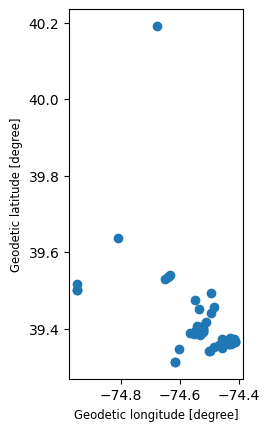

In [72]:
ATLgeo_full.plot()

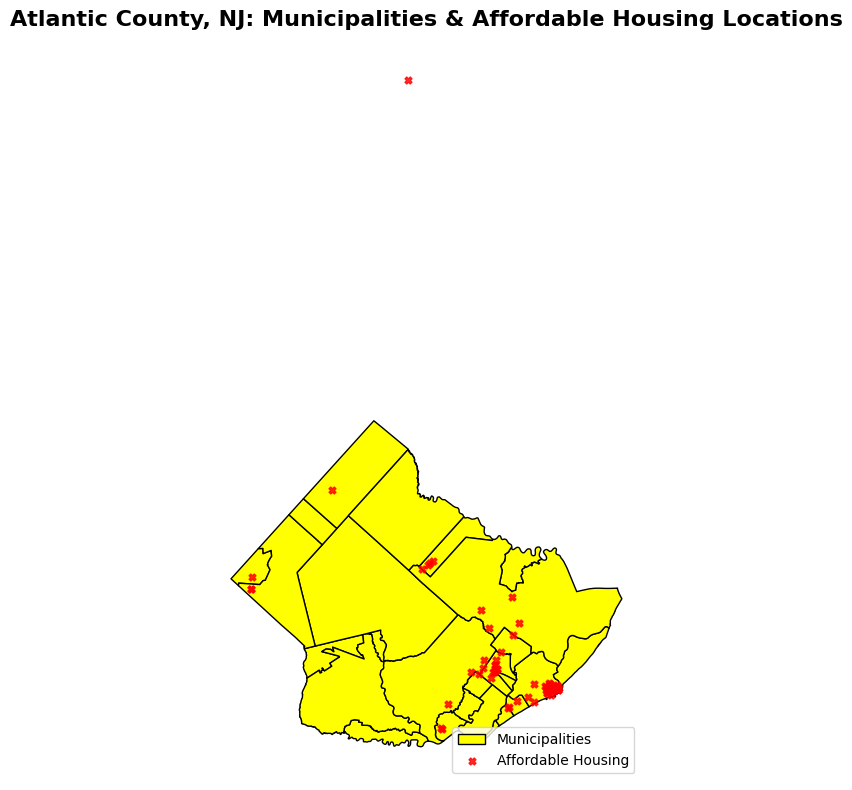

In [73]:
import matplotlib.pyplot as plt

# 1. Align Coordinate Reference Systems (CRS)
# Convert the geocoded points to match the municipal boundary CRS (EPSG:3424)
ATLgeo_projected = ATLgeo_full.to_crs(atlantic_mun_gdf.crs)

# 2. Create the plot overlay
fig, ax = plt.subplots(figsize=(10, 8))

# Plot the base map (Municipalities of Atlantic County)
atlantic_mun_gdf.plot(ax=ax, edgecolor='black', color='YELLOW', linewidth=1, label='Municipalities')

# Plot the geocoded points of Affordable Housing
ATLgeo_projected.plot(ax=ax, marker='X', color='red', markersize=25, alpha=0.8, label='Affordable Housing')

# Add title, legend, and cleanup axes
plt.title('Atlantic County, NJ: Municipalities & Affordable Housing Locations', fontsize=16, fontweight='bold', pad=15)
plt.axis('off')
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

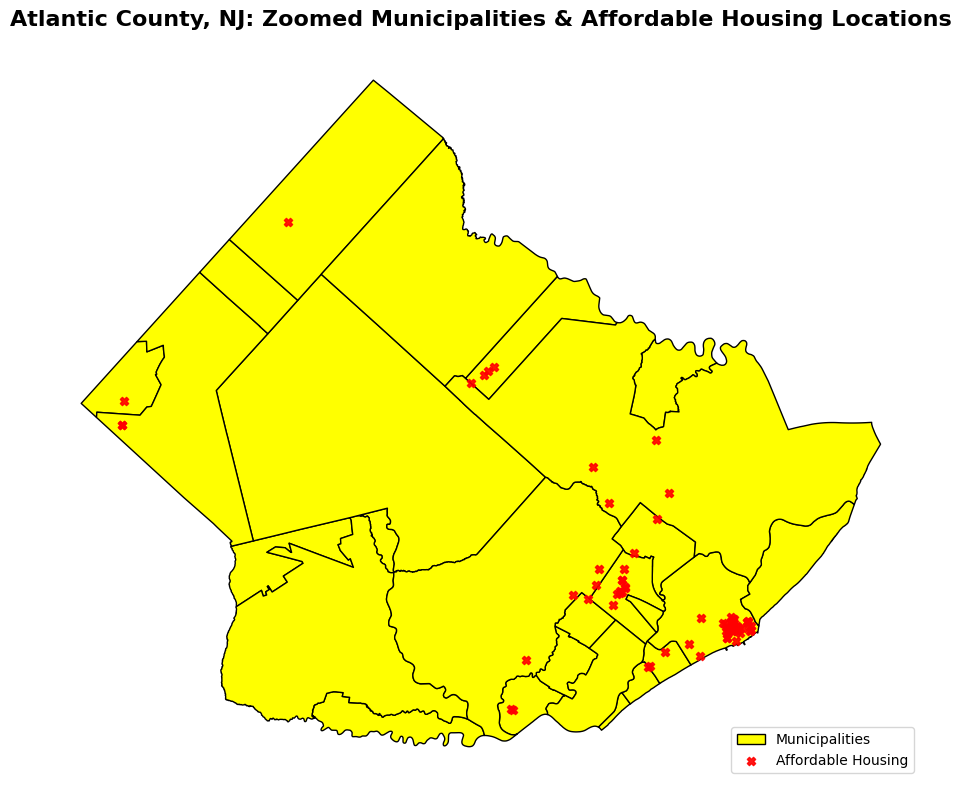

Removed 1 outlier point(s) located outside Atlantic County boundaries.


In [74]:
# 1. Align Coordinate Reference Systems (CRS) first
ATLgeo_projected = ATLgeo_full.to_crs(atlantic_mun_gdf.crs)

# 2. Filter points spatially (keep only those inside the municipal boundaries)
# This removes any geocoding outliers that are outside Atlantic County
ATLgeo_in_county = gpd.sjoin(ATLgeo_projected, atlantic_mun_gdf, how='inner', predicate='within')

# 3. Create the zoomed-in plot overlay
fig, ax = plt.subplots(figsize=(10, 8))

# Plot the base map (Municipalities of Atlantic County)
atlantic_mun_gdf.plot(ax=ax, edgecolor='black', color='yellow', linewidth=1, label='Municipalities')

# Plot only the points that are within Atlantic County boundaries
ATLgeo_in_county.plot(ax=ax, marker='X', color='red', markersize=35, alpha=0.9, label='Affordable Housing')

# Add title, legend, and cleanup axes
plt.title('Atlantic County, NJ: Zoomed Municipalities & Affordable Housing Locations', fontsize=16, fontweight='bold', pad=15)
plt.axis('off')
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

# Print status info
print(f"Removed {len(ATLgeo_projected) - len(ATLgeo_in_county)} outlier point(s) located outside Atlantic County boundaries.")

https://www.arcgis.com/home/item.html?id=95177982e99e46778881d34cb9ac4d99&sublayer=0

https://www.policymap.com/newmaps/e/rutgers

https://www.nj.gov/health/fhs/primarycare/rural-health/DesignatedRuralAreasinNewJersey.pdf

#Plotting Municipality Names

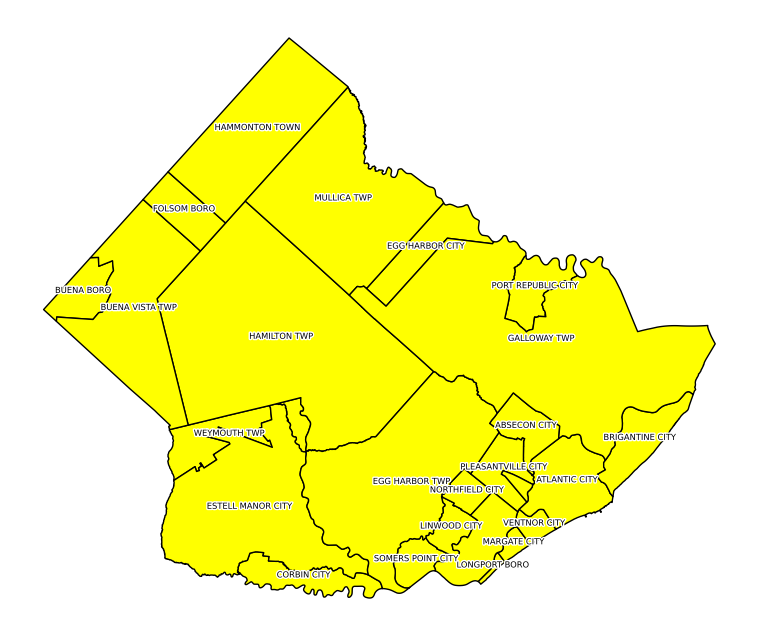

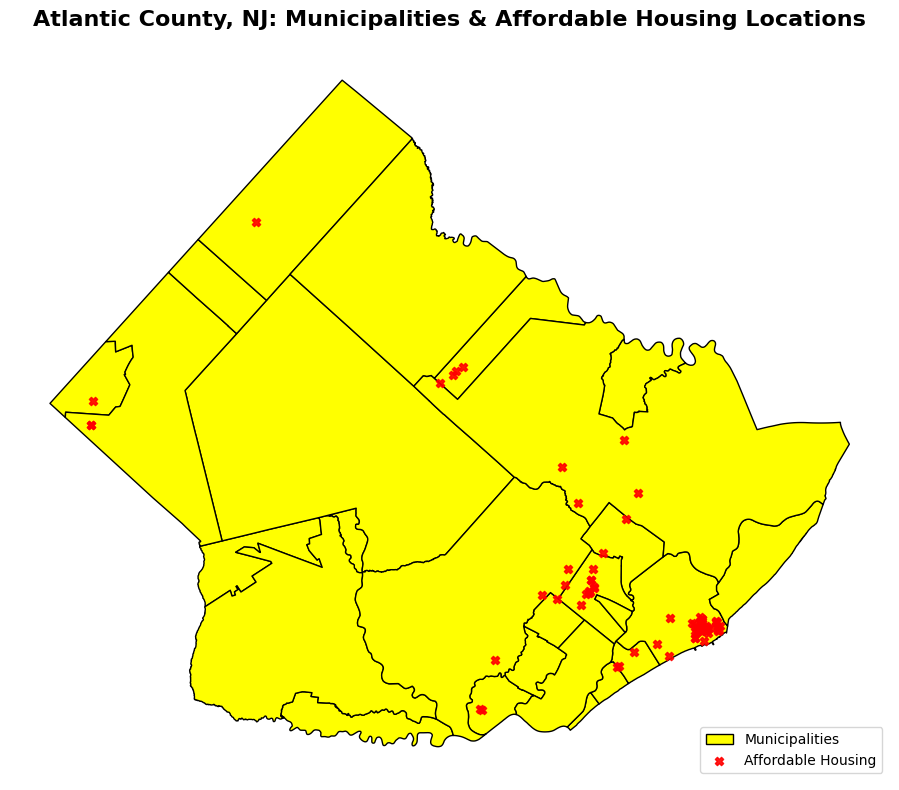

Removed 1 outlier point(s) located outside Atlantic County boundaries.


In [75]:
from matplotlib.patheffects import withStroke
import matplotlib.pyplot as plt

# Plot the base map
fig, ax = plt.subplots(figsize=(10, 8))
atlantic_mun_gdf.plot(ax=ax, edgecolor='black', color='yellow')

# Extract the centroid coordinates of each municipality polygon for labeling
centroids = atlantic_mun_gdf.geometry.centroid

for x, y, label in zip(centroids.x, centroids.y, atlantic_mun_gdf.MUN):
    ax.annotate(
        label,
        xy=(x, y),
        horizontalalignment='center',
        fontsize=6,
        color='black',
        path_effects=[withStroke(linewidth=2, foreground='white')]
    )

plt.axis('off')
plt.show()

ATLgeo_projected = ATLgeo_full.to_crs(atlantic_mun_gdf.crs)
ATLgeo_in_county = gpd.sjoin(ATLgeo_projected, atlantic_mun_gdf, how='inner', predicate='within')
fig, ax = plt.subplots(figsize=(10, 8))
atlantic_mun_gdf.plot(ax=ax, edgecolor='black', color='yellow', linewidth=1, label='Municipalities')
ATLgeo_in_county.plot(ax=ax, marker='X', color='red', markersize=35, alpha=0.9, label='Affordable Housing')

# Add title, legend, and cleanup axes
plt.title('Atlantic County, NJ: Municipalities & Affordable Housing Locations', fontsize=16, fontweight='bold', pad=15)
plt.axis('off')
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

# Print status info
print(f"Removed {len(ATLgeo_projected) - len(ATLgeo_in_county)} outlier point(s) located outside Atlantic County boundaries.")


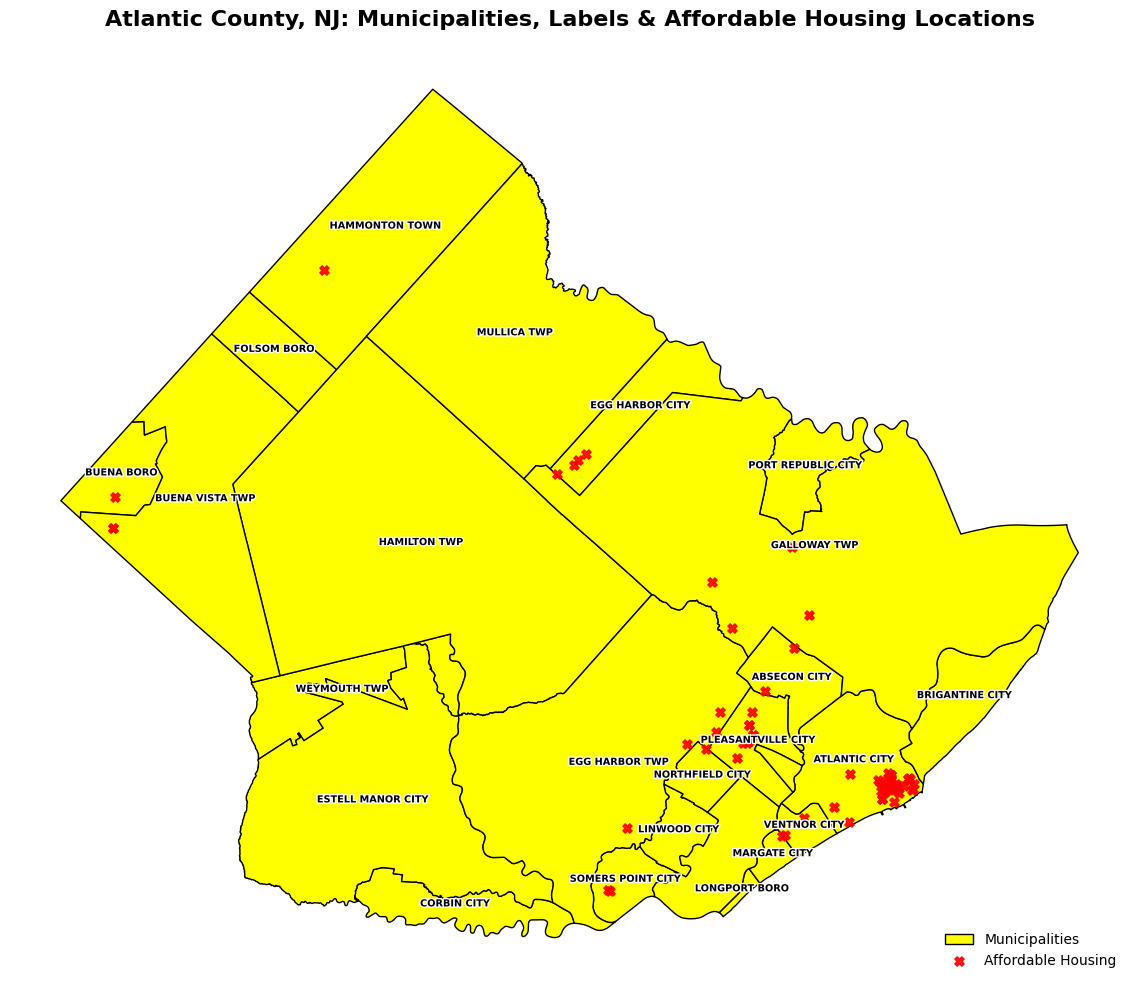

In [76]:
from matplotlib.patheffects import withStroke
import matplotlib.pyplot as plt
import geopandas as gpd

# 1. Project points to match the municipality CRS (EPSG:3424)
ATLgeo_projected = ATLgeo_full.to_crs(atlantic_mun_gdf.crs)

# 2. Keep only housing points inside Atlantic County
ATLgeo_in_county = gpd.sjoin(ATLgeo_projected, atlantic_mun_gdf, how='inner', predicate='within')

# 3. Create the combined plot
fig, ax = plt.subplots(figsize=(12, 10))

# Plot the yellow municipal boundaries
atlantic_mun_gdf.plot(ax=ax, edgecolor='black', color='yellow', linewidth=1, label='Municipalities')

# Plot the red affordable housing point markers
ATLgeo_in_county.plot(ax=ax, marker='X', color='red', markersize=45, alpha=0.9, label='Affordable Housing')

# Add the municipal text labels at each polygon's centroid
centroids = atlantic_mun_gdf.geometry.centroid
for x, y, label in zip(centroids.x, centroids.y, atlantic_mun_gdf.MUN):
    ax.annotate(
        label,
        xy=(x, y),
        horizontalalignment='center',
        fontsize=7,
        color='black',
        weight='bold',
        path_effects=[withStroke(linewidth=2, foreground='white')]
    )

# Map styling
plt.title('Atlantic County, NJ: Municipalities, Labels & Affordable Housing Locations', fontsize=16, fontweight='bold', pad=15)
plt.axis('off')
plt.legend(loc='lower right', frameon=True, facecolor='white', edgecolor='none')
plt.tight_layout()
plt.show()

Including Population density into Atlantic County Municipalities for detailed Atlantic County Affordable Housing Developments.

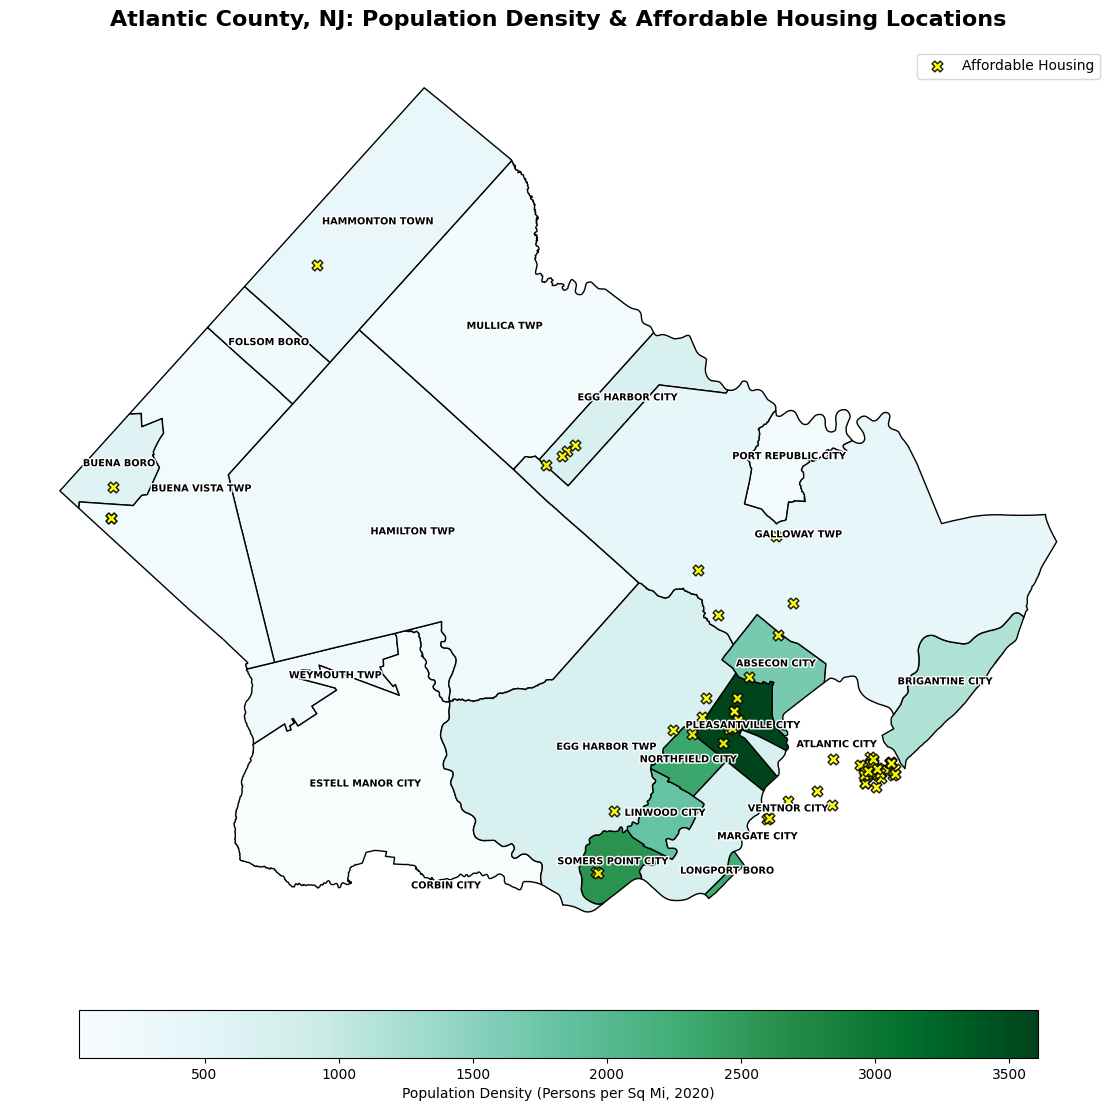

In [79]:
# 1. Clean municipality names to ensure a robust merge
atlantic_mun_gdf['clean_city'] = (atlantic_mun_gdf['MUN_LABEL']
                                  .str.replace(r'\s+(city|township|borough|town)$', '', regex=True, case=False)
                                  .str.strip()
                                  .str.lower())

# 2. Merge population density data into our spatial DataFrame
atlantic_mun_density = atlantic_mun_gdf.merge(pop_df, on='clean_city', how='left')

# 3. Project housing points to match the municipality CRS (EPSG:3424)
ATLgeo_projected = ATLgeo_full.to_crs(atlantic_mun_density.crs)

# 4. Filter housing points to stay strictly within Atlantic County using standard inner spatial join
ATLgeo_in_county = gpd.sjoin(ATLgeo_projected, atlantic_mun_density, how='inner', predicate='within')

# 5. Create the thematic map
fig, ax = plt.subplots(figsize=(14, 12))

# Plot the municipalities as a choropleth map of Population Density
atlantic_mun_density.plot(
    ax=ax,
    column='Persons per Sq Mi Census 2020',
    cmap='BuGn',
    edgecolor='black',
    linewidth=1,
    legend=True,
    legend_kwds={
        'label': 'Population Density (Persons per Sq Mi, 2020)',
        'orientation': 'horizontal',
        'shrink': 0.7,
        'pad': 0.05
    }
)

# Overlay the affordable housing points
ATLgeo_in_county.plot(
    ax=ax,
    marker='X',
    color='yellow',
    edgecolor='black',
    markersize=60,
    alpha=0.9,
    label='Affordable Housing'
)

# Add names/labels to the municipalities
from matplotlib.patheffects import withStroke
centroids = atlantic_mun_density.geometry.centroid
for x, y, label in zip(centroids.x, centroids.y, atlantic_mun_density.MUN):
    ax.annotate(
        label,
        xy=(x, y),
        horizontalalignment='center',
        fontsize=7,
        color='black',
        weight='bold',
        path_effects=[withStroke(linewidth=2, foreground='white')]
    )

# Map presentation tuning
plt.title('Atlantic County, NJ: Population Density & Affordable Housing Locations', fontsize=16, fontweight='bold', pad=15)
plt.legend(loc='upper right', frameon=True, facecolor='white')
plt.axis('off')
plt.tight_layout()
plt.show()

#Final map interpretation
This map indicates that majority of Atlantic County affordable housing developments are closing to the Atlantic City area.  This is likely due to this being the area with the highest population density in the county.  Additional map could include median income or household size to compare if density is the only factor for affordable housing development presence.

#Cites

## References & Resources

### Data Sources
1. **New Jersey State & Municipal Boundaries (EPSG:3424)**
   * **Source:** New Jersey Office of GIS (NJOGIS)
   * **Portal:** [NJ Spatial Data Warehouse / NJ Open Data Portal](https://njogis-newjersey.opendata.arcgis.com/datasets/state-boundary-of-nj-3424/explore)
   * **Dataset Access:** Provided via the Anjanique-Knight GitHub Repository (`NJ_Municipal_Boundaries_3424.zip`)

2. **New Jersey Municipal Population & Density (Census 2020 / Estimates 2022)**
   * **Source:** New Jersey Department of Health / State Census Data
   * **Documentation:** [Designated Rural Areas in New Jersey (PDF)](https://www.nj.gov/health/fhs/primarycare/rural-health/DesignatedRuralAreasinNewJersey.pdf)
   * **Dataset Access:** Provided via the Anjanique-Knight GitHub Repository (`New_Jersey_Population_Density.xlsx`)

3. **Atlantic County Affordable Housing Developments**
   * **Source:** New Jersey Department of Community Affairs (NJ DCA)
   * **Portal:** [NJ DCA Codes & Standards Publications](https://www.nj.gov/dca/codes/publications/developments.shtml)
   * **Dataset Access:** Compiled and geocoded via the Anjanique-Knight GitHub Repository (`atlantic.xlsx`)

### Technology & APIs
1. **Geocoding API (Nominatim / OpenStreetMap)**
   * **Service:** OpenStreetMap Nominatim Geocoding engine
   * **Terms of Service:** [OSM Nominatim Usage Policy](https://operations.osmfoundation.org/policies/nominatim/) (Access mapped with a Python rate limiter restricting calls to 1 request per second).

2. **Spatial Analysis & Visualization Libraries**
   * **GeoPandas:** Spatial operations, CRS reprojections, and spatial joins.
   * **Pandas:** Data cleaning, merging, and matching evaluation using outer joins.
   * **Matplotlib & Seaborn:** Map visualizations, choropleths, labeling, and layout formatting.

Gemini Error Processing Cites
citations = {
    "Data & GIS Sources": [
        "New Jersey Counties & Municipal Boundaries Shapefiles: Hosted on GitHub (AjGIS repository by Anjanique-Knight).",
        "Atlantic County Affordable Housing Dataset (atlantic.xlsx): Hosted on GitHub (AjGIS repository).",
        "New Jersey Population Density Dataset (New_Jersey_Population_Density.xlsx): Hosted on GitHub (AjGIS repository)."
    ],
    "Geocoding Services": [
        "OpenStreetMap Nominatim API: Used via Geopy's RateLimiter to safely geocode addresses with an enforced delay policy."
    ],
    "Python Core Libraries": [
        "GeoPandas: Spatial operations, Coordinate Reference System (CRS) transformations, and map plotting.",
        "Pandas: Data manipulation, cleaning, and joining tables.",
        "Matplotlib: Spatial visualization, mapping layout styling, and custom styling with path effects (withStroke).",
        "Geopy / Nominatim: Client library to interface with OpenStreetMap's search API."
    ]
}

for category, entries in citations.items():
    print(f"=== {category} ===")
    for idx, entry in enumerate(entries, start=1):
        print(f"{idx}. {entry}")
    print()